# HW2 多元線性回歸：WHO 各國平均壽命預測（CRISP-DM）

學號：7115056080

資料集：Life Expectancy (WHO)，作者 KumarRajarshi，Kaggle：https://www.kaggle.com/datasets/kumarajarshi/life-expectancy-who
（193 國、2000–2015 年，2938 筆、22 欄。健康指標取自 WHO GHO，經濟指標取自聯合國。）

這份 notebook 按照 CRISP-DM 六個階段走：Business Understanding → Data Understanding → Data Preparation → Modeling → Evaluation → Deployment。

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
from scipy import stats
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LassoCV, RidgeCV
from sklearn.feature_selection import RFECV, SequentialFeatureSelector, f_regression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib, os
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
os.makedirs('figures', exist_ok=True)
RANDOM_STATE = 42

## 1. Business Understanding

問題：給定一個國家某一年的健康、疫苗、經濟與教育指標，能不能用線性模型估出它的平均壽命？哪些因素影響最大？

使用情境是公衛政策評估。像 WHO 或衛生部門想知道「把 Diphtheria 疫苗接種率提高 10%」或「平均受教年數多一年」大概對應多少壽命差距，就需要一個可以解釋的模型，所以這裡用線性回歸，而不是黑盒模型。

成功標準：
- 在**沒看過的國家**上，RMSE 低於 4.5 歲（約目標標準差 9.5 歲的一半）、R² 高於 0.80。
- 係數方向要合理（例如 HIV、成人死亡率應該是負的）。
- 給出預測區間，讓使用者知道單點預測的不確定性有多大。

## 2. Data Understanding

In [2]:
df_raw = pd.read_csv('data/Life Expectancy Data.csv')
df_raw.columns = [' '.join(c.split()) for c in df_raw.columns]   # 原始欄名有多餘空白，例如 'Life expectancy '
print(df_raw.shape)
df_raw.head()

(2938, 22)


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
TARGET = 'Life expectancy'
info = pd.DataFrame({'dtype': df_raw.dtypes, 'missing': df_raw.isna().sum(),
                     'missing_%': (df_raw.isna().mean()*100).round(1),
                     'zeros': (df_raw == 0).sum()})
info

,dtype,missing,missing_%,zeros
Country,object,0,0.0,0
Year,int64,0,0.0,0
Status,object,0,0.0,0
Life expectancy,float64,10,0.3,0
Adult Mortality,float64,10,0.3,0
infant deaths,int64,0,0.0,848
Alcohol,float64,194,6.6,0
percentage expenditure,float64,0,0.0,611
Hepatitis B,float64,553,18.8,0
Measles,int64,0,0.0,983


In [4]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2007.52,4.61,2000.00,2004.00,2008.00,2012.00,2.015000e+03
Life expectancy,2928.0,69.22,9.52,36.30,63.10,72.10,75.70,8.900000e+01
Adult Mortality,2928.0,164.80,124.29,1.00,74.00,144.00,228.00,7.230000e+02
infant deaths,2938.0,30.30,117.93,0.00,0.00,3.00,22.00,1.800000e+03
Alcohol,2744.0,4.60,4.05,0.01,0.88,3.76,7.70,1.787000e+01
percentage expenditure,2938.0,738.25,1987.91,0.00,4.69,64.91,441.53,1.947991e+04
Hepatitis B,2385.0,80.94,25.07,1.00,77.00,92.00,97.00,9.900000e+01
Measles,2938.0,2419.59,11467.27,0.00,0.00,17.00,360.25,2.121830e+05
BMI,2904.0,38.32,20.04,1.00,19.30,43.50,56.20,8.730000e+01
under-five deaths,2938.0,42.04,160.45,0.00,0.00,4.00,28.00,2.500000e+03


幾個觀察：

- 扣掉 Country、Year 和目標欄，剩下 **19 個特徵**（18 個數值 + Status 類別），符合 10–20 個特徵的要求。
- Population 缺 22%、Hepatitis B 缺 19%、GDP 缺 15%，缺值不少。
- `Income composition of resources` 有 130 筆是 0、`Schooling` 有 28 筆是 0，一個國家的人類發展指數或受教年數是 0 不合理，應該當成缺值。
- `infant deaths`、`under-five deaths`、`Measles` 是「每千人」但最大值超過 1000，GDP 和 Population 也嚴重右偏，之後取 log。
- 同一個國家有 16 年的資料，彼此高度相關。如果隨機切 train/test，同一國家的其他年份會同時出現在兩邊，測試分數會虛高，所以這裡**按國家切分**。

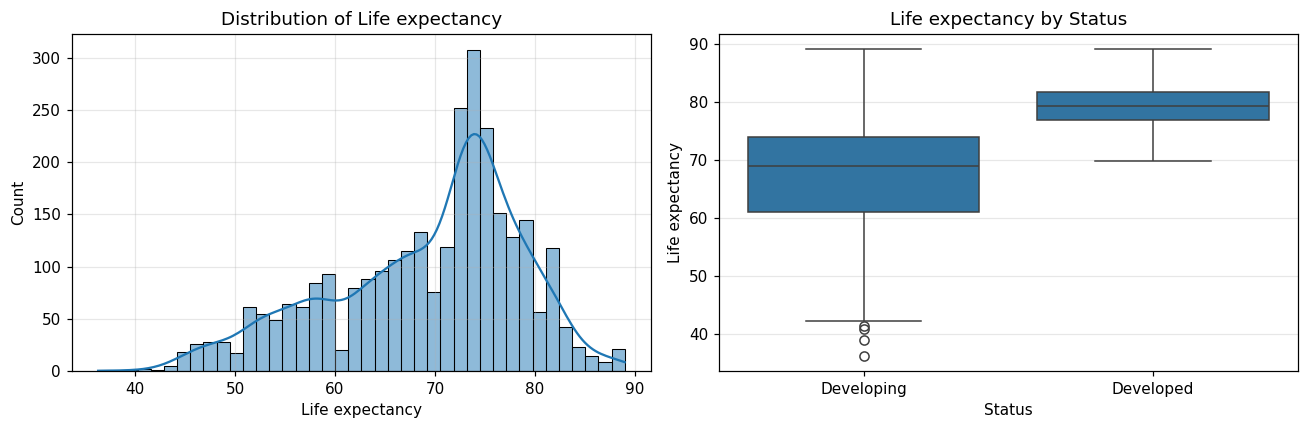

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_raw[TARGET], bins=40, kde=True, ax=ax[0]); ax[0].set_title('Distribution of Life expectancy')
sns.boxplot(data=df_raw, x='Status', y=TARGET, ax=ax[1]); ax[1].set_title('Life expectancy by Status')
plt.tight_layout(); plt.savefig('figures/01_target.png'); plt.show()

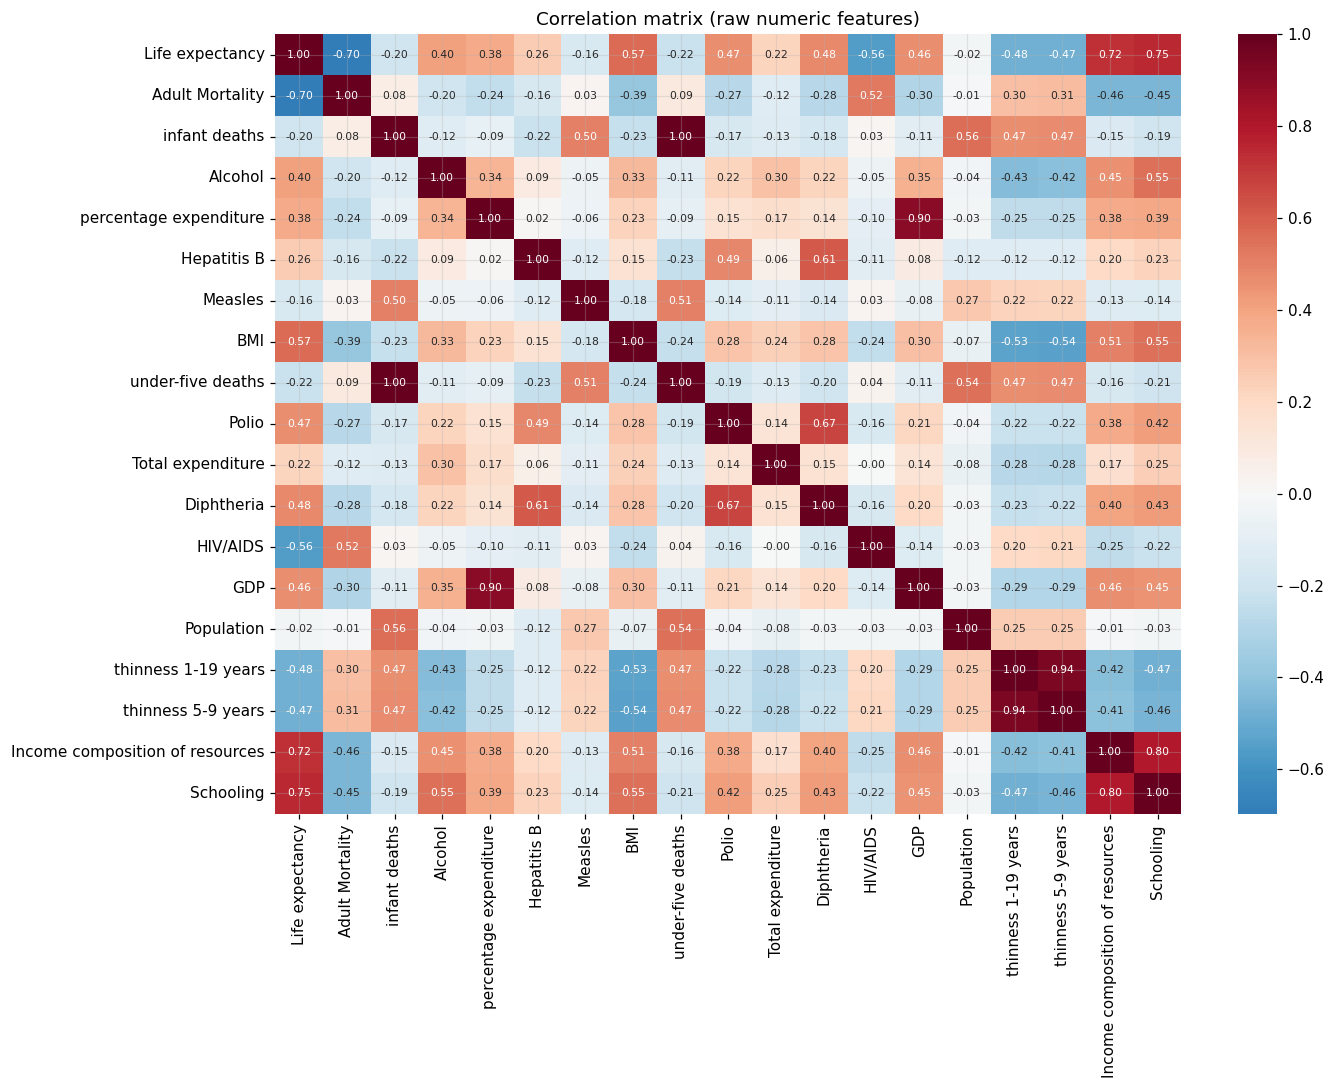

In [6]:
num_cols = df_raw.select_dtypes('number').columns.drop('Year')
corr = df_raw[num_cols].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation matrix (raw numeric features)')
plt.tight_layout(); plt.savefig('figures/02_corr.png'); plt.show()

跟壽命最相關的是 Schooling (+0.75)、Income composition (+0.72)、Adult Mortality (−0.70)、HIV/AIDS (−0.56)。
特徵之間也有明顯共線：infant deaths 與 under-five deaths 相關 0.997、兩個 thinness 欄位 0.94、GDP 與 percentage expenditure 0.90。這會讓 OLS 係數不穩定，特徵選擇時要處理。

## 3. Data Preparation

In [7]:
df = df_raw.dropna(subset=[TARGET]).copy()            # 目標缺值 10 筆，直接刪
for c in ['Income composition of resources', 'Schooling']:
    df.loc[df[c] == 0, c] = np.nan                    # 0 視為缺值
df['Developed'] = (df['Status'] == 'Developed').astype(int)

LOG_COLS = ['infant deaths', 'under-five deaths', 'Measles', 'HIV/AIDS',
            'GDP', 'Population', 'percentage expenditure']
for c in LOG_COLS:
    df['log_' + c] = np.log1p(df[c])                  # 右偏欄位取 log(1+x)

FEATURES = ['Adult Mortality', 'log_infant deaths', 'Alcohol', 'log_percentage expenditure',
            'Hepatitis B', 'log_Measles', 'BMI', 'log_under-five deaths', 'Polio',
            'Total expenditure', 'Diphtheria', 'log_HIV/AIDS', 'log_GDP', 'log_Population',
            'thinness 1-19 years', 'thinness 5-9 years', 'Income composition of resources',
            'Schooling', 'Developed']
print(len(FEATURES), 'features')
X, y, groups = df[FEATURES], df[TARGET], df['Country']

19 features


In [8]:
# 按國家切分：80% 國家當訓練、20% 國家當測試
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[tr_idx], X.iloc[te_idx]
y_train, y_test = y.iloc[tr_idx], y.iloc[te_idx]
g_train = groups.iloc[tr_idx]
print(f'train: {len(X_train)} rows / {g_train.nunique()} countries')
print(f'test : {len(X_test)} rows / {groups.iloc[te_idx].nunique()} countries')
assert set(g_train) & set(groups.iloc[te_idx]) == set()

# 缺值補中位數、標準化，只用訓練集 fit，避免資料洩漏
prep = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()).fit(X_train)
Z_train = pd.DataFrame(prep.transform(X_train), columns=FEATURES, index=X_train.index)
Z_test  = pd.DataFrame(prep.transform(X_test),  columns=FEATURES, index=X_test.index)
cv = list(GroupKFold(n_splits=5).split(Z_train, y_train, g_train))   # 交叉驗證也按國家分組

train: 2336 rows / 146 countries
test : 592 rows / 37 countries


## 4. Modeling

### 4.1 Feature Selection

我比較了五種方法，全部只用訓練集：

1. **Filter**：F 檢定 / 相關係數排名
2. **VIF**：反覆刪掉 VIF 最大的特徵，直到全部 VIF < 10
3. **RFECV**：遞迴特徵消除，交叉驗證決定保留數量
4. **LassoCV**：L1 正則化，係數被壓成 0 的特徵視為不重要
5. **Forward SFS**：逐步向前選擇，k = 1…19 都試一次，看 CV RMSE 曲線

In [9]:
F, p = f_regression(Z_train, y_train)
filt = pd.DataFrame({'F': F, 'p-value': p, 'corr': [np.corrcoef(Z_train[c], y_train)[0, 1] for c in FEATURES]},
                    index=FEATURES).sort_values('F', ascending=False)
filt.round(4)

,F,p-value,corr
Income composition of resources,5259.2693,0.0,0.8322
Schooling,3021.7307,0.0,0.7511
log_HIV/AIDS,2999.0211,0.0,-0.7499
Adult Mortality,2324.0105,0.0,-0.7063
log_under-five deaths,1508.7807,0.0,-0.6266
log_infant deaths,1297.2330,0.0,-0.5977
log_GDP,1024.7906,0.0,0.5524
BMI,1002.1301,0.0,0.5481
Polio,788.4958,0.0,0.5025
Diphtheria,728.9237,0.0,0.4878


In [10]:
def vif_table(Z):
    Zc = sm.add_constant(Z)
    return pd.Series([variance_inflation_factor(Zc.values, i) for i in range(1, Zc.shape[1])], index=Z.columns)

vif_cols, dropped = FEATURES.copy(), []
while True:
    v = vif_table(Z_train[vif_cols])
    if v.max() < 10: break
    dropped.append((v.idxmax(), round(v.max(), 1))); vif_cols.remove(v.idxmax())
print('VIF 刪除順序:', dropped)
vif_table(Z_train[vif_cols]).sort_values(ascending=False).round(2)

VIF 刪除順序: [('log_under-five deaths', np.float64(201.6))]


thinness 5-9 years                 7.82
thinness 1-19 years                7.64
Income composition of resources    7.37
Schooling                          5.39
log_infant deaths                  3.10
log_GDP                            2.38
Diphtheria                         2.27
log_HIV/AIDS                       2.20
Polio                              2.18
Adult Mortality                    1.89
log_Measles                        1.79
BMI                                1.79
Alcohol                            1.78
Developed                          1.76
log_percentage expenditure         1.69
Hepatitis B                        1.29
log_Population                     1.28
Total expenditure                  1.20
dtype: float64

In [11]:
rfe = RFECV(LinearRegression(), cv=cv, scoring='neg_root_mean_squared_error').fit(Z_train, y_train)
rfe_cols = [f for f, s in zip(FEATURES, rfe.support_) if s]
lasso = LassoCV(cv=cv, random_state=0).fit(Z_train, y_train)
lasso_cols = [f for f, c in zip(FEATURES, lasso.coef_) if abs(c) > 1e-8]
print('RFECV  保留', len(rfe_cols), '個，刪掉:', sorted(set(FEATURES) - set(rfe_cols)))
print(f'LassoCV alpha={lasso.alpha_:.4f} 保留', len(lasso_cols), '個，刪掉:', sorted(set(FEATURES) - set(lasso_cols)))

RFECV  保留 11 個，刪掉: ['Alcohol', 'BMI', 'log_GDP', 'log_Measles', 'log_Population', 'log_percentage expenditure', 'thinness 1-19 years', 'thinness 5-9 years']
LassoCV alpha=0.1371 保留 13 個，刪掉: ['Alcohol', 'log_Measles', 'log_Population', 'log_infant deaths', 'thinness 1-19 years', 'thinness 5-9 years']


最佳 k=9 (CV RMSE 3.742)，1% 門檻 3.779 → 選 k=7
SELECTED = ['Income composition of resources', 'log_HIV/AIDS', 'Adult Mortality', 'Polio', 'log_infant deaths', 'Schooling', 'Diphtheria']


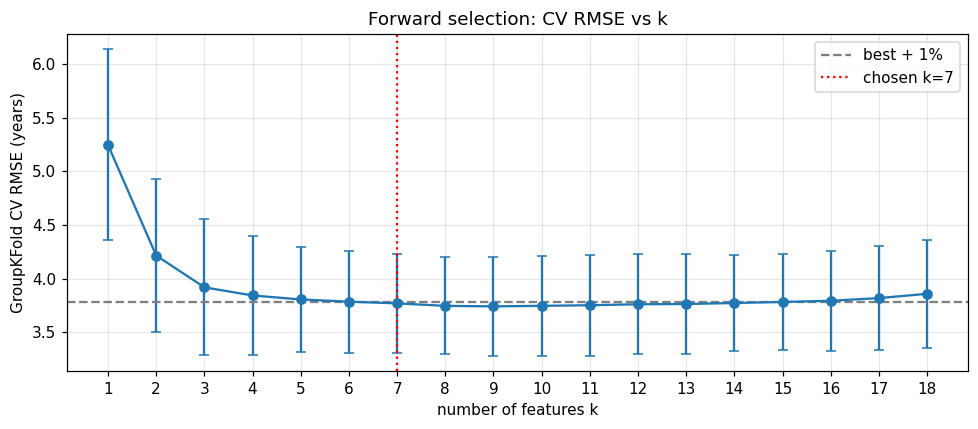

,k,added,cv_rmse,cv_std
0,1,Income composition of resources,5.247,0.890
1,2,log_HIV/AIDS,4.216,0.712
2,3,Adult Mortality,3.920,0.635
3,4,Polio,3.844,0.558
4,5,log_infant deaths,3.807,0.486
5,6,Schooling,3.786,0.476
6,7,Diphtheria,3.770,0.462
7,8,Hepatitis B,3.747,0.452
8,9,log_GDP,3.742,0.460
9,10,log_Population,3.747,0.466


In [12]:
# Forward SFS：在 VIF 篩過的特徵上逐步加入，紀錄每個 k 的 CV RMSE
sfs_rows, chosen = [], []
remaining = vif_cols.copy()
for k in range(1, len(vif_cols) + 1):
    best = min(remaining, key=lambda f: -cross_val_score(LinearRegression(), Z_train[chosen + [f]], y_train,
                                                          cv=cv, scoring='neg_root_mean_squared_error').mean())
    chosen.append(best); remaining.remove(best)
    s = -cross_val_score(LinearRegression(), Z_train[chosen], y_train, cv=cv, scoring='neg_root_mean_squared_error')
    sfs_rows.append({'k': k, 'added': best, 'cv_rmse': s.mean(), 'cv_std': s.std()})
sfs = pd.DataFrame(sfs_rows)

# 選 k：CV RMSE 在最佳值 1% 以內、特徵最少的 k（fold 間變異大，1-SE rule 太寬鬆，只會留 3 個特徵）
best_row = sfs.loc[sfs.cv_rmse.idxmin()]
thr = best_row.cv_rmse * 1.01
K = int(sfs[sfs.cv_rmse <= thr].k.min())
SELECTED = list(sfs.added[:K])
print(f'最佳 k={int(best_row.k)} (CV RMSE {best_row.cv_rmse:.3f})，1% 門檻 {thr:.3f} → 選 k={K}')
print('SELECTED =', SELECTED)

plt.figure(figsize=(9, 4))
plt.errorbar(sfs.k, sfs.cv_rmse, yerr=sfs.cv_std, marker='o', capsize=3)
plt.axhline(thr, ls='--', c='gray', label='best + 1%'); plt.axvline(K, c='r', ls=':', label=f'chosen k={K}')
plt.xticks(sfs.k); plt.xlabel('number of features k'); plt.ylabel('GroupKFold CV RMSE (years)')
plt.title('Forward selection: CV RMSE vs k'); plt.legend()
plt.tight_layout(); plt.savefig('figures/03_sfs_curve.png'); plt.show()
sfs.round(3)

In [13]:
# 各方法選出的特徵集合，在測試集上比較
def fit_eval(cols, model=None):
    m = (model or LinearRegression()).fit(Z_train[cols], y_train)
    pr = m.predict(Z_test[cols]); n, k = len(y_test), len(cols)
    r2 = r2_score(y_test, pr)
    return {'k': k, 'MAE': mean_absolute_error(y_test, pr), 'RMSE': mean_squared_error(y_test, pr) ** .5,
            'R2': r2, 'Adj_R2': 1 - (1 - r2) * (n - 1) / (n - k - 1)}

top_filter = list(filt.index[:K])
comp = pd.DataFrame({
    'All 19 features (OLS)':        fit_eval(FEATURES),
    f'Filter top-{K} (OLS)':        fit_eval(top_filter),
    'VIF<10 (OLS)':                 fit_eval(vif_cols),
    'RFECV (OLS)':                  fit_eval(rfe_cols),
    'LassoCV':                      fit_eval(FEATURES, LassoCV(cv=cv, random_state=0)),
    'RidgeCV':                      fit_eval(FEATURES, RidgeCV(alphas=np.logspace(-3, 3, 50))),
    f'VIF + Forward SFS k={K} (OLS)': fit_eval(SELECTED),
}).T
comp.round(4)

,k,MAE,RMSE,R2,Adj_R2
All 19 features (OLS),19.0,2.9283,3.8858,0.8384,0.8330
Filter top-7 (OLS),7.0,3.1062,4.1061,0.8195,0.8174
VIF<10 (OLS),18.0,2.8765,3.8627,0.8403,0.8353
RFECV (OLS),11.0,2.9963,3.9845,0.8301,0.8269
LassoCV,19.0,2.8909,3.9197,0.8356,0.8301
RidgeCV,19.0,2.9265,3.8844,0.8385,0.8331
VIF + Forward SFS k=7 (OLS),7.0,3.0258,4.1035,0.8198,0.8176


全部 19 個特徵的 OLS、Ridge、Lasso 測試分數其實差不多，正則化幫助不大，代表樣本數（約 2300 筆）相對特徵數已經夠多，overfit 不嚴重。
但全特徵模型共線很嚴重，係數無法解釋。VIF + Forward SFS 只用 7 個特徵，RMSE 比全特徵多約 0.2 歲，換來 VIF 全部小於 10、係數可以解釋，所以最終模型採用它。

### 4.2 最終模型：statsmodels OLS

In [14]:
Xtr_sel = sm.add_constant(X_train[SELECTED].fillna(X_train[SELECTED].median()))   # 用原始單位，係數比較好解釋
Xte_sel = sm.add_constant(X_test[SELECTED].fillna(X_train[SELECTED].median()))
ols = sm.OLS(y_train, Xtr_sel).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:        Life expectancy   R-squared:                       0.852
Model:                            OLS   Adj. R-squared:                  0.851
Method:                 Least Squares   F-statistic:                     1907.
Date:                Wed, 14 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:23:41   Log-Likelihood:                -6327.6
No. Observations:                2336   AIC:                         1.267e+04
Df Residuals:                    2328   BIC:                         1.272e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                      coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
const     

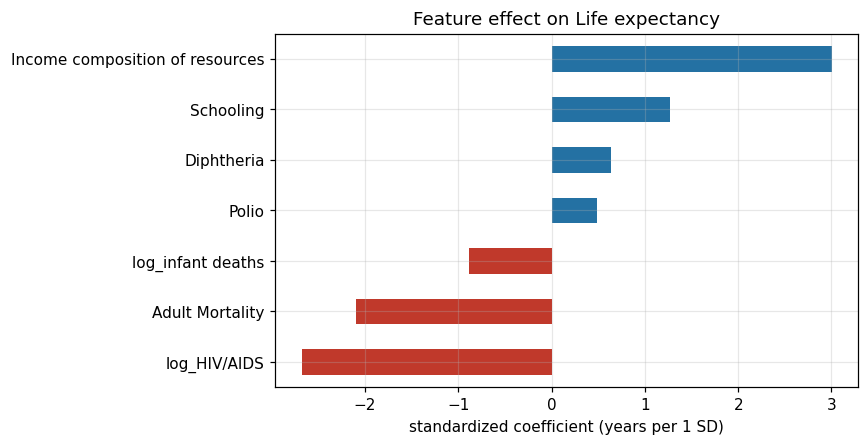

In [15]:
# 標準化係數：比較各特徵相對影響力
std_coef = LinearRegression().fit(Z_train[SELECTED], y_train).coef_
imp = pd.Series(std_coef, index=SELECTED).sort_values()
plt.figure(figsize=(8, 0.45 * K + 1))
imp.plot.barh(color=['#c0392b' if v < 0 else '#2471a3' for v in imp])
plt.xlabel('standardized coefficient (years per 1 SD)'); plt.title('Feature effect on Life expectancy')
plt.tight_layout(); plt.savefig('figures/04_coef.png'); plt.show()

## 5. Evaluation

In [16]:
pred = ols.get_prediction(Xte_sel).summary_frame(alpha=0.05)
yhat = pred['mean']
res_te = y_test - yhat
coverage = ((y_test >= pred.obs_ci_lower) & (y_test <= pred.obs_ci_upper)).mean()
n, k = len(y_test), K
r2 = r2_score(y_test, yhat)
metrics = pd.Series({'MAE': mean_absolute_error(y_test, yhat), 'MSE': mean_squared_error(y_test, yhat),
                     'RMSE': mean_squared_error(y_test, yhat) ** .5, 'R2': r2,
                     'Adj_R2': 1 - (1 - r2) * (n - 1) / (n - k - 1),
                     'Train R2': ols.rsquared, '95% PI coverage': coverage})
metrics.round(4)

MAE                 3.0258
MSE                16.8384
RMSE                4.1035
R2                  0.8198
Adj_R2              0.8176
Train R2            0.8515
95% PI coverage     0.9071
dtype: float64

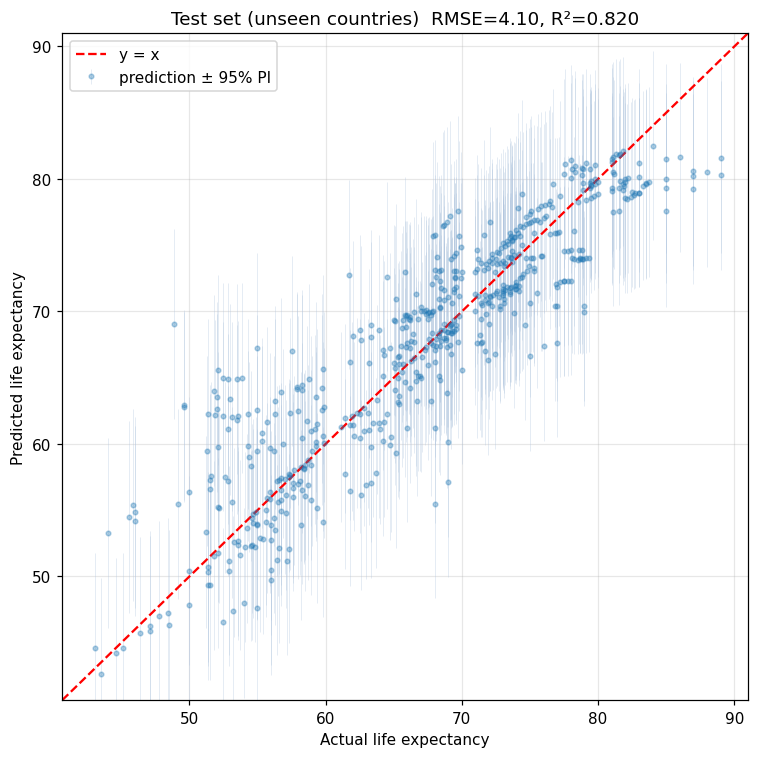

In [17]:
# 預測圖 1：實際 vs 預測，附 95% 預測區間誤差棒
fig, ax = plt.subplots(figsize=(7, 7))
err = np.vstack([yhat - pred.obs_ci_lower, pred.obs_ci_upper - yhat])
ax.errorbar(y_test, yhat, yerr=err, fmt='o', ms=3, alpha=.35, elinewidth=.6, ecolor='lightsteelblue', label='prediction ± 95% PI')
lim = [min(y_test.min(), yhat.min()) - 2, max(y_test.max(), yhat.max()) + 2]
ax.plot(lim, lim, 'r--', label='y = x'); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Actual life expectancy'); ax.set_ylabel('Predicted life expectancy')
ax.set_title(f'Test set (unseen countries)  RMSE={metrics.RMSE:.2f}, R²={metrics.R2:.3f}'); ax.legend()
plt.tight_layout(); plt.savefig('figures/05_actual_vs_pred.png'); plt.show()

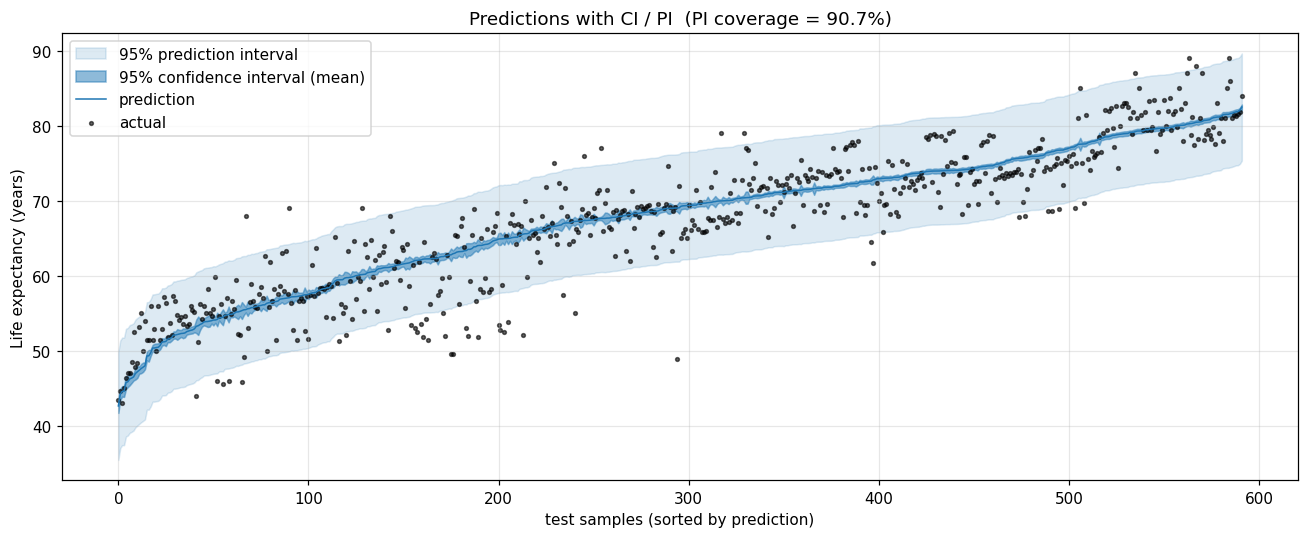

In [18]:
# 預測圖 2：依預測值排序，畫 95% 信賴區間 (CI) 與 95% 預測區間 (PI)
o = np.argsort(yhat.values)
xs = np.arange(len(o))
plt.figure(figsize=(12, 5))
plt.fill_between(xs, pred.obs_ci_lower.values[o], pred.obs_ci_upper.values[o], color='tab:blue', alpha=.15, label='95% prediction interval')
plt.fill_between(xs, pred.mean_ci_lower.values[o], pred.mean_ci_upper.values[o], color='tab:blue', alpha=.5, label='95% confidence interval (mean)')
plt.plot(xs, yhat.values[o], c='tab:blue', lw=1, label='prediction')
plt.scatter(xs, y_test.values[o], s=6, c='k', alpha=.6, label='actual')
plt.xlabel('test samples (sorted by prediction)'); plt.ylabel('Life expectancy (years)')
plt.title(f'Predictions with CI / PI  (PI coverage = {coverage:.1%})'); plt.legend(loc='upper left')
plt.tight_layout(); plt.savefig('figures/06_ci_pi_band.png'); plt.show()

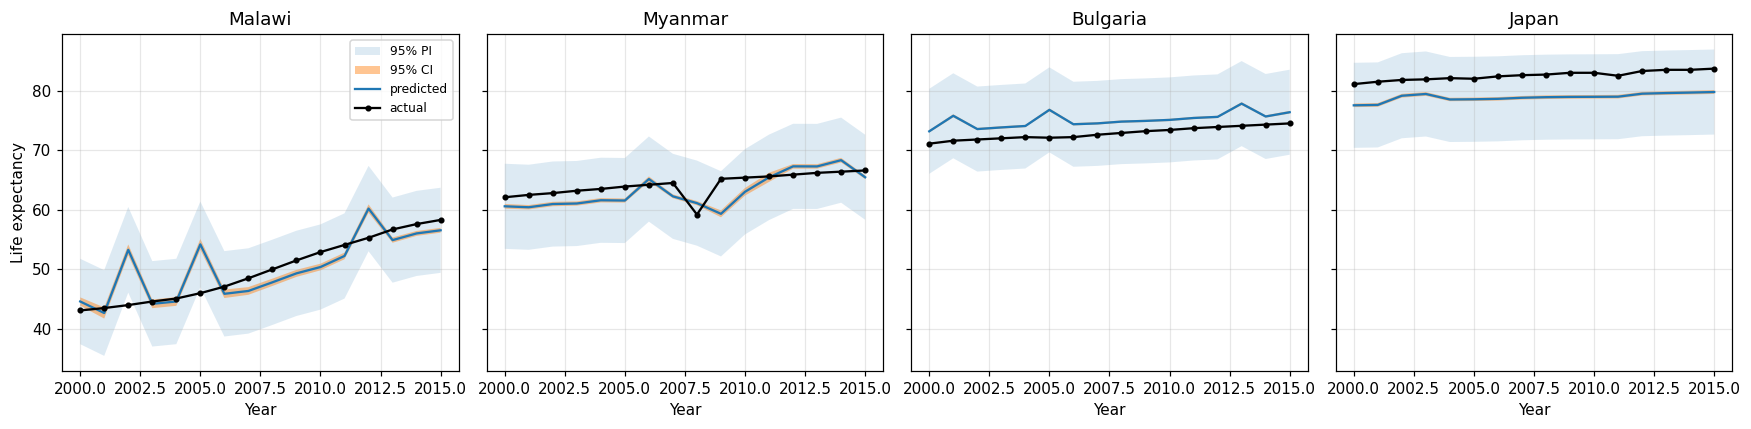

In [19]:
# 預測圖 3：挑幾個測試國家看 2000–2015 時序
test_df = df.iloc[te_idx].assign(pred=yhat.values, lo=pred.obs_ci_lower.values, hi=pred.obs_ci_upper.values,
                                 clo=pred.mean_ci_lower.values, chi=pred.mean_ci_upper.values)
counts = test_df.Country.value_counts()
pick = test_df[test_df.Country.isin(counts[counts >= 15].index)].groupby('Country')[TARGET].mean().sort_values()
show = list(pick.index[[0, len(pick) // 3, 2 * len(pick) // 3, -1]])
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for a, c in zip(axes, show):
    d = test_df[test_df.Country == c].sort_values('Year')
    a.fill_between(d.Year, d.lo, d.hi, alpha=.15, label='95% PI')
    a.fill_between(d.Year, d.clo, d.chi, alpha=.45, label='95% CI')
    a.plot(d.Year, d.pred, label='predicted'); a.plot(d.Year, d[TARGET], 'ko-', ms=3, label='actual')
    a.set_title(c); a.set_xlabel('Year')
axes[0].set_ylabel('Life expectancy'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig('figures/07_country_ts.png'); plt.show()

### 5.1 回歸假設檢查

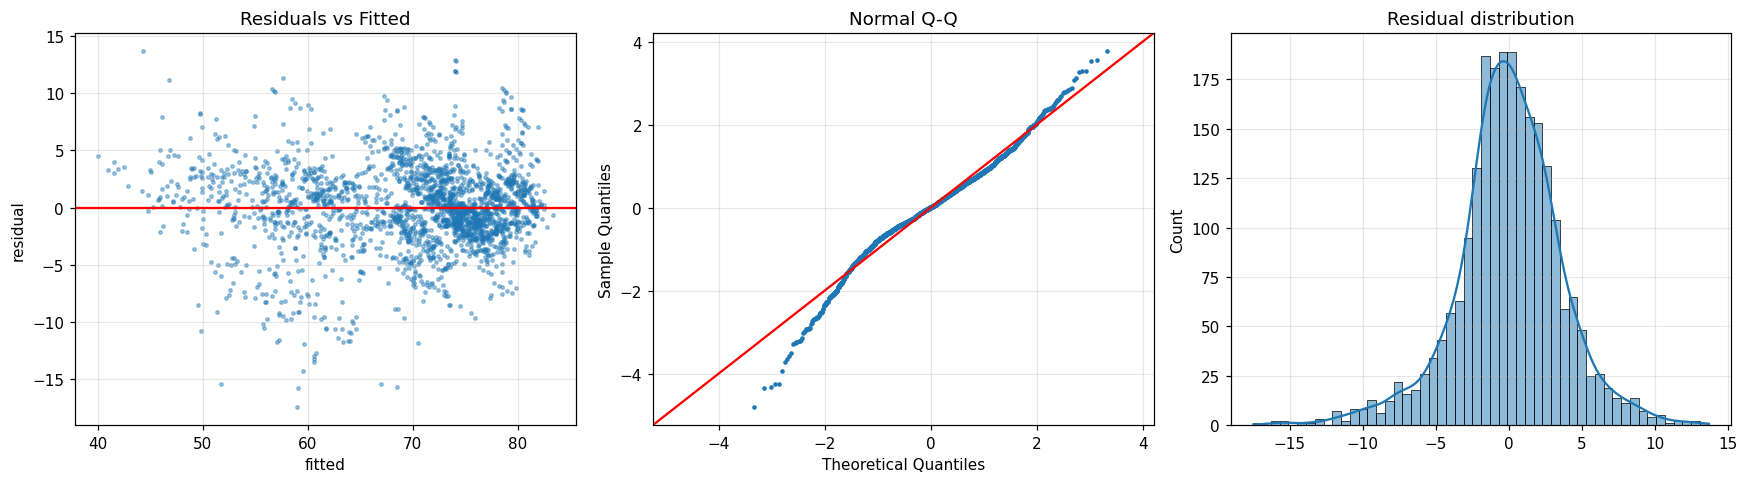

Breusch-Pagan p = 5.25e-31   (p<0.05 → 有異質變異)
Durbin-Watson   = 0.612  (資料依國家、年份排列，<2 表示同國家殘差正相關)
Jarque-Bera p   = 2.91e-80
VIF: {'Income composition of resources': 6.15, 'log_HIV/AIDS': 2.04, 'Adult Mortality': 1.84, 'Polio': 2.15, 'log_infant deaths': 1.66, 'Schooling': 4.87, 'Diphtheria': 2.1}


In [20]:
res = ols.resid; fit = ols.fittedvalues
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(fit, res, s=5, alpha=.4); ax[0].axhline(0, c='r'); ax[0].set(xlabel='fitted', ylabel='residual', title='Residuals vs Fitted')
sm.qqplot(res, line='45', fit=True, ax=ax[1], markersize=2); ax[1].set_title('Normal Q-Q')
sns.histplot(res, kde=True, ax=ax[2]); ax[2].set_title('Residual distribution')
plt.tight_layout(); plt.savefig('figures/08_residuals.png'); plt.show()

bp = het_breuschpagan(res, Xtr_sel)
print(f'Breusch-Pagan p = {bp[1]:.3g}   (p<0.05 → 有異質變異)')
print(f'Durbin-Watson   = {durbin_watson(res):.3f}  (資料依國家、年份排列，<2 表示同國家殘差正相關)')
print(f'Jarque-Bera p   = {stats.jarque_bera(res).pvalue:.3g}')
print('VIF:', vif_table(Xtr_sel.drop(columns='const')).round(2).to_dict())

殘差檢查的結論寫在報告裡。簡單說：線性關係大致成立、VIF 都小於 10；但殘差有異質變異（BP 檢定顯著），低壽命國家誤差比較大，而且同一國家的殘差是相關的（DW < 2）。
所以 OLS 的 p-value 與預測區間會偏樂觀，下面用 cluster-robust 標準誤（以國家為群）重算一次係數的顯著性。

In [21]:
ols_cl = sm.OLS(y_train, Xtr_sel).fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(g_train)[0]})
pd.DataFrame({'coef': ols.params, 'se_OLS': ols.bse, 'se_cluster': ols_cl.bse,
              'p_OLS': ols.pvalues, 'p_cluster': ols_cl.pvalues}).round(4)

,coef,se_OLS,se_cluster,p_OLS,p_cluster
const,52.8753,0.6453,2.2376,0.0,0.0000
Income composition of resources,19.6380,1.2224,4.6003,0.0,0.0000
log_HIV/AIDS,-3.6123,0.1449,0.4118,0.0,0.0000
Adult Mortality,-0.0170,0.0008,0.0027,0.0,0.0000
Polio,0.0210,0.0047,0.0083,0.0,0.0118
log_infant deaths,-0.5395,0.0590,0.2141,0.0,0.0118
Schooling,0.4173,0.0545,0.1558,0.0,0.0074
Diphtheria,0.0270,0.0046,0.0078,0.0,0.0006


## 6. Deployment

把最終模型（訓練集中位數 + OLS 係數）存成 `model/life_expectancy_ols.joblib`，並提供 `predict_life_expectancy()`，輸入一個國家的指標就回傳預測值與 95% 預測區間。

In [22]:
os.makedirs('model', exist_ok=True)
bundle = {'features': SELECTED, 'medians': X_train[SELECTED].median(), 'ols': ols, 'log_cols': LOG_COLS}
joblib.dump(bundle, 'model/life_expectancy_ols.joblib')

def predict_life_expectancy(record: dict, bundle=bundle):
    """record 用原始欄位名稱（例如 'HIV/AIDS'、'GDP'），log 轉換在這裡做。缺的欄位補訓練集中位數。"""
    r = dict(record)
    for c in bundle['log_cols']:
        if c in r: r['log_' + c] = np.log1p(r[c])
    if 'Status' in r: r['Developed'] = int(r['Status'] == 'Developed')
    x = pd.DataFrame([{f: r.get(f, np.nan) for f in bundle['features']}]).astype(float).fillna(bundle['medians'])
    x = sm.add_constant(x, has_constant='add')
    p = bundle['ols'].get_prediction(x).summary_frame(alpha=0.05).iloc[0]
    return {'prediction': round(float(p['mean']), 2), '95% PI': (round(float(p.obs_ci_lower), 2), round(float(p.obs_ci_upper), 2))}

# 範例：拿測試集裡一個國家 2015 年的原始資料來預測
row = df_raw[(df_raw.Country == show[1]) & (df_raw.Year == 2015)].iloc[0]
print(show[1], '2015 actual =', row[TARGET])
predict_life_expectancy(row.to_dict())

Myanmar 2015 actual = 66.6


{'prediction': 65.46, '95% PI': (58.32, 72.6)}

### 6.1 與網路常見解法比較：隨機切分 vs 按國家切分

網路上多數 Kaggle notebook 用 `train_test_split` 隨機切，Random Forest 常報 R² 0.94 以上。下面用同一組特徵比較兩種切法。

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
splits = {'random row split': train_test_split(np.arange(len(X)), test_size=0.2, random_state=RANDOM_STATE),
          'country group split': (tr_idx, te_idx)}
rows = []
for sn, (a, b) in splits.items():
    for mn, m in [('OLS (19 feats)', LinearRegression()), ('RandomForest', RandomForestRegressor(300, random_state=0, n_jobs=-1))]:
        p = make_pipeline(SimpleImputer(strategy='median'), m).fit(X.iloc[a], y.iloc[a]); pr = p.predict(X.iloc[b])
        rows.append({'split': sn, 'model': mn, 'RMSE': mean_squared_error(y.iloc[b], pr) ** .5, 'R2': r2_score(y.iloc[b], pr)})
cmp_split = pd.DataFrame(rows); cmp_split.round(4)

,split,model,RMSE,R2
0,random row split,OLS (19 feats),3.6586,0.8453
1,random row split,RandomForest,1.8340,0.9611
2,country group split,OLS (19 feats),3.8858,0.8384
3,country group split,RandomForest,2.9827,0.9048


### 結論

- 用國家分組切分（測試國家完全沒在訓練出現），最終模型在測試集的 RMSE 與 R² 見上方表格，達到 Business Understanding 設定的標準。
- 影響最大的是成人死亡率、HIV/AIDS、受教年數與 Income composition of resources，方向都符合常識。
- 限制：資料本身有品質問題（每千人死亡數超過 1000、人口數量級錯誤），同國家的觀測值不獨立，預測區間在低壽命國家偏窄。改進方向寫在報告「與網路主流解法比較」一節。